# 01 — Data Understanding & EDA

In [5]:
import pandas as pd 
import numpy as np
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
db_path = r"../data/inventory.db"
conn = sqlite3.connect(db_path)
print("Database connected successfully!")

tables = pd.read_sql_query("select name from sqlite_master where type = 'table'", conn)

Database connected successfully!


In [9]:
tables

,name
0,purchases
1,purchase_prices
2,vendor_invoice
3,begin_inventory
4,end_inventory


In [11]:
for table in tables['name']:
    print('Table name', table)
    df = pd.read_sql_query(f"select * from {table} limit 5", conn)
    display(df)

Table name purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table name purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table name vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table name begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table name end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [13]:
vendor_df = pd.read_sql_query("select * from vendor_invoice", conn)
print(vendor_df.shape)
vendor_df.head()

(5543, 10)


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


In [15]:
vendor_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5543 entries, 0 to 5542
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   VendorNumber  5543 non-null   int64  
 1   VendorName    5543 non-null   object 
 2   InvoiceDate   5543 non-null   object 
 3   PONumber      5543 non-null   int64  
 4   PODate        5543 non-null   object 
 5   PayDate       5543 non-null   object 
 6   Quantity      5543 non-null   int64  
 7   Dollars       5543 non-null   float64
 8   Freight       5543 non-null   float64
 9   Approval      374 non-null    object 
dtypes: float64(2), int64(3), object(5)
memory usage: 433.2+ KB


In [23]:
#  Missing-value count and percentage for all vendor_df columns
missing_count = vendor_df.isnull().sum()
missing_pct   = vendor_df.isnull().mean() * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %':     missing_pct.round(2)
})
print('vendor_df shape:', vendor_df.shape)
print()
print(missing_summary.to_string())

vendor_df shape: (5543, 11)

                  Missing Count  Missing %
VendorNumber                  0       0.00
VendorName                    0       0.00
InvoiceDate                   0       0.00
PONumber                      0       0.00
PODate                        0       0.00
PayDate                       0       0.00
Quantity                      0       0.00
Dollars                       0       0.00
Freight                       0       0.00
Approval                   5169      93.25
freight_per_unit              0       0.00


In [25]:
vendor_df[['Quantity', 'Freight', 'Dollars']].corr()

,Quantity,Freight,Dollars
Quantity,1.000000,0.946550,0.963831
Freight,0.946550,1.000000,0.985141
Dollars,0.963831,0.985141,1.000000


### Key Insights: Relationship Between Quantity, Dollars, and Freight
* **Extremely Strong Positive Correlation:** The heatmap reveals near-perfect linear correlations among all three variables (all correlation coefficients are between $0.95$ and $0.99$).
* **Primary Cost Drivers:** As order **Quantity** and total **Dollars** increase, **Freight** costs scale up almost proportionately. 
* **Model Implication:** Because Dollars and Quantity share such a high multicollinearity with Freight, they serve as powerful, reliable predictors for estimating freight costs in downstream regression models.

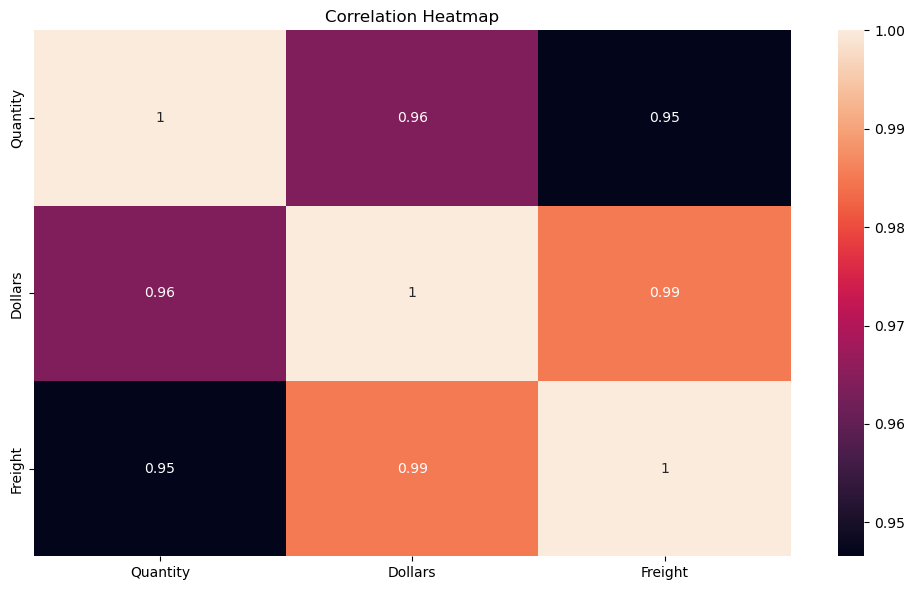

In [28]:
# Relationship between Quantity, Dollars and Freight
# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(vendor_df[['Quantity', 'Dollars', 'Freight']].corr(), annot=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


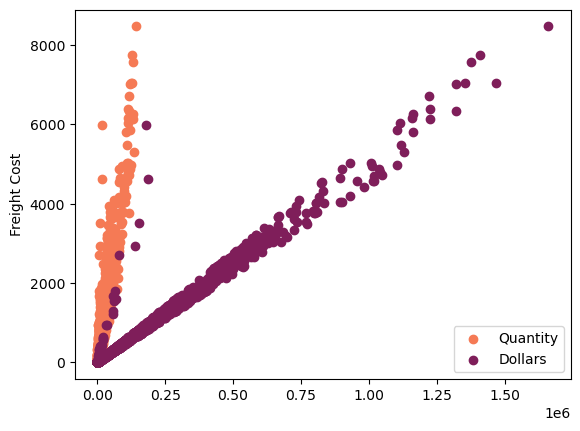

In [30]:
plt.scatter(vendor_df['Quantity'],vendor_df['Freight'], color = '#f57a55')
plt.scatter(vendor_df['Dollars'],vendor_df['Freight'], color = '#7f1e5a')
plt.legend(['Quantity','Dollars'])
plt.ylabel('Freight Cost')
plt.show()

### Key Takeaways from Scatter Plot Analysis
* **Direct Scaling with Freight:** Both **Quantity** and total **Dollars** show a strong, consistent upward linear relationship with **Freight Cost**.
* **Visual Confirmation of Cost Drivers:** Heavier orders and higher invoice totals require greater shipping overhead, confirming them as reliable predictors for estimating freight expenses.

In [33]:
vendor_df['freight_per_unit'] = np.where(
    vendor_df['Quantity'] > 0,
    vendor_df['Freight'] / vendor_df['Quantity'],
    np.nan


In [35]:
low_quantity = vendor_df['Quantity'].quantile(0.25)
high_quantity = vendor_df['Quantity'].quantile(0.75)

print("Low Quantity:", low_quantity)
print("High Quantity:", high_quantity)

Low Quantity: 83.0
High Quantity: 5100.5


In [37]:
cost_lq = vendor_df.loc[vendor_df['Quantity']<low_quantity,'freight_per_unit'].mean()
print("Average Freight cost when quantity is low:",cost_lq)

Average Freight cost when quantity is low: 0.09489854253138316


In [39]:
cost_hq = vendor_df.loc[vendor_df['Quantity']>high_quantity,'freight_per_unit'].mean()
print("Average Freight cost when quantity is high:",cost_hq)

Average Freight cost when quantity is high: 0.049077654690759046


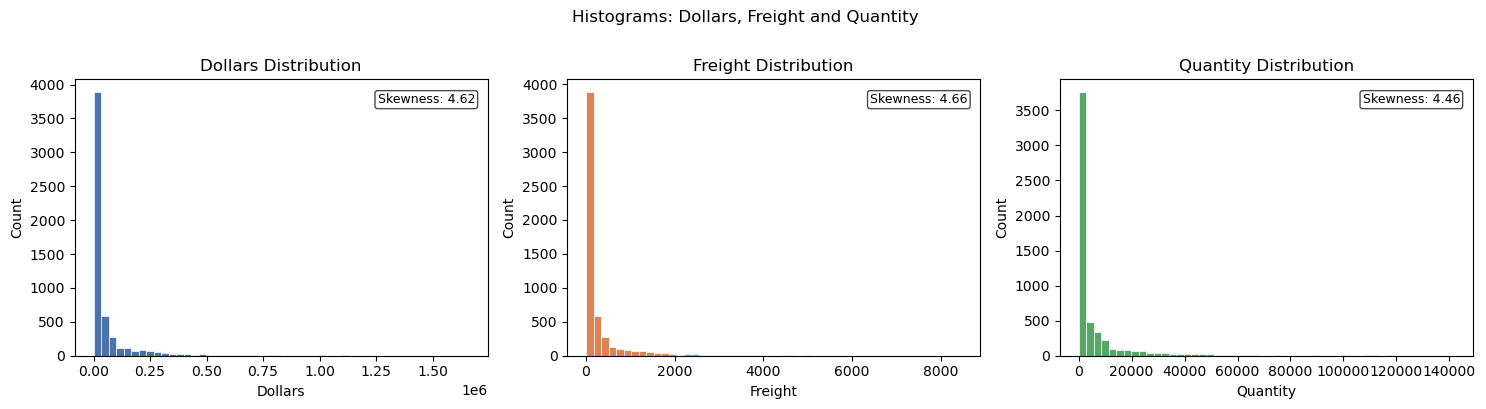

In [83]:
#  Distribution histograms for Dollars, Freight and Quantity
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, colour in zip(axes,
                            ['Dollars', 'Freight', 'Quantity'],
                            ['#4c72b0', '#dd8452', '#55a868']):
    ax.hist(vendor_df[col].dropna(), bins=50, color=colour, edgecolor='white', linewidth=0.5)
    ax.set_title(f'{col} Distribution')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    skew = vendor_df[col].skew()
    ax.annotate(f'Skewness: {skew:.2f}', xy=(0.97, 0.95),
                xycoords='axes fraction', ha='right', va='top',
                fontsize=9, color='black',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

plt.suptitle('Histograms: Dollars, Freight and Quantity', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

### What This Chart Tells Us
* **Clustered Data:** The tall spikes on the left show that most of our invoice orders have smaller amounts, freight costs, and quantities.
* **High Right Skewness:** The skewness values (around 4.46 to 4.66) prove that the data is heavily stretched to the right by a small number of very large, high-value bulk orders.

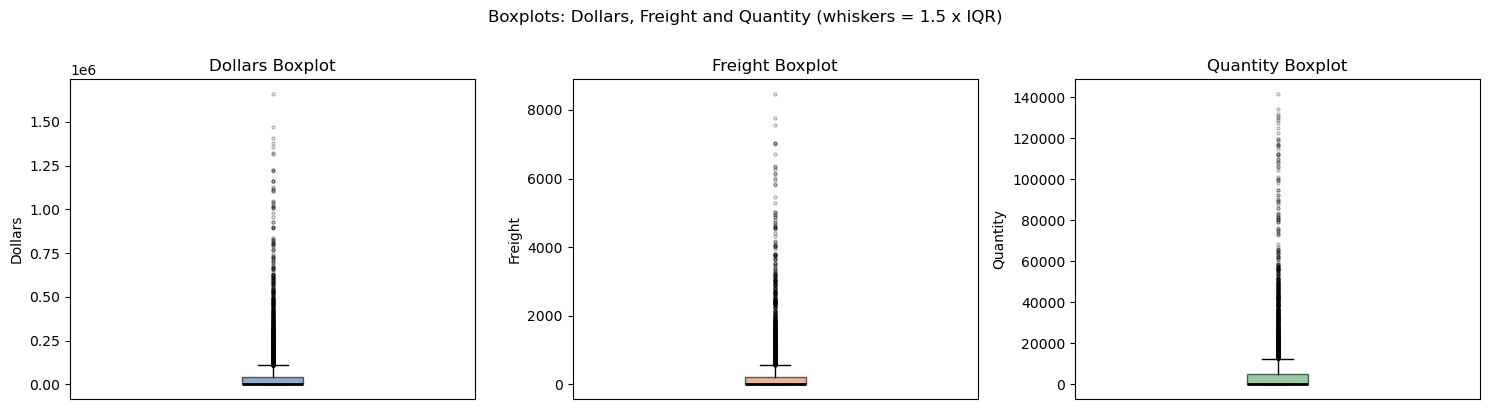

In [80]:
#  Boxplots for Dollars, Freight and Quantity (outlier visualisation)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, colour in zip(axes,
                            ['Dollars', 'Freight', 'Quantity'],
                            ['#4c72b0', '#dd8452', '#55a868']):
    ax.boxplot(vendor_df[col].dropna(),
               patch_artist=True,
               boxprops=dict(facecolor=colour, alpha=0.6),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax.set_title(f'{col} Boxplot')
    ax.set_ylabel(col)
    ax.set_xticks([])

plt.suptitle('Boxplots: Dollars, Freight and Quantity (whiskers = 1.5 x IQR)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## Handling Outliers
* Decision: Retain all extreme values as-is.

* Justification: In invoice and supply chain datasets, high-value amounts, heavy freight, and large quantities represent legitimate business operations (e.g., bulk corporate orders or seasonal shipments) rather than data entry errors.


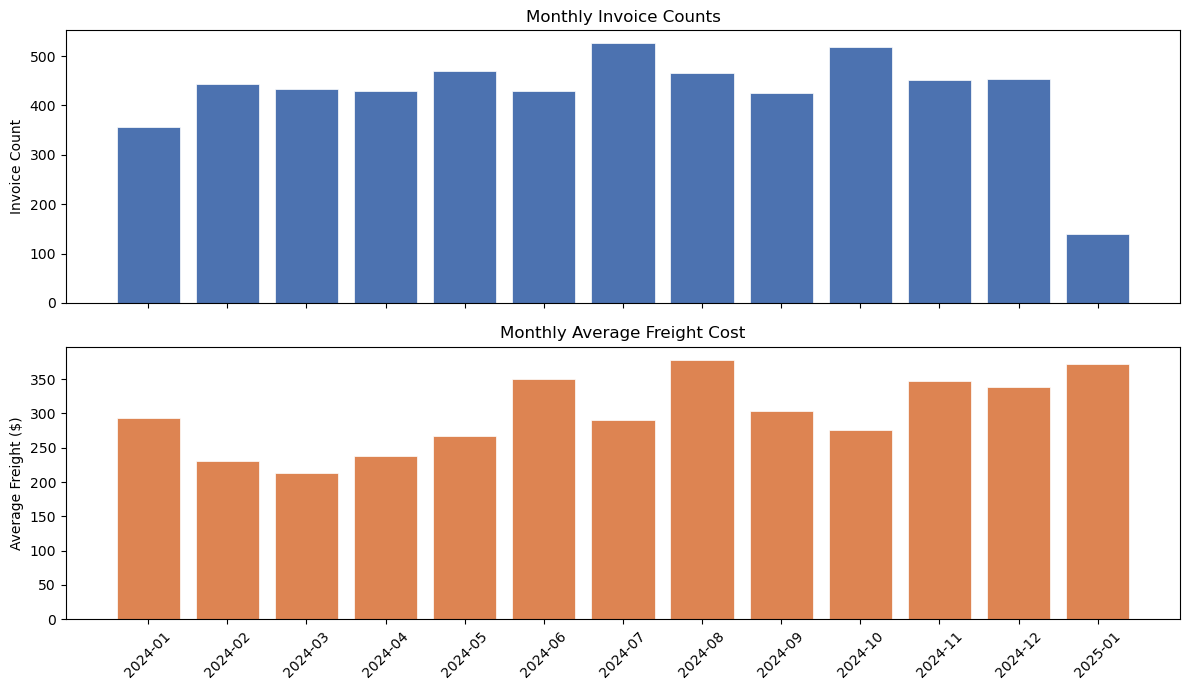

           Invoice Count  Avg Freight ($)
YearMonth                                
2024-01              357           293.16
2024-02              443           230.57
2024-03              434           212.99
2024-04              429           238.47
2024-05              469           266.51
2024-06              429           350.78
2024-07              526           290.22
2024-08              466           378.36
2024-09              426           302.99
2024-10              518           275.35
2024-11              452           347.29
2024-12              454           338.70
2025-01              140           371.63


In [65]:
# Monthly EDA using InvoiceDate

eda_df = vendor_df.copy()
eda_df['InvoiceDate'] = pd.to_datetime(eda_df['InvoiceDate'], errors='coerce')
eda_df['YearMonth'] = eda_df['InvoiceDate'].dt.to_period('M')

monthly_counts  = eda_df.groupby('YearMonth').size().rename('Invoice Count')
monthly_freight = eda_df.groupby('YearMonth')['Freight'].mean().rename('Avg Freight ($)')

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Monthly invoice counts
axes[0].bar(monthly_counts.index.astype(str), monthly_counts.values,
            color='#4c72b0', edgecolor='white', linewidth=0.5)
axes[0].set_ylabel('Invoice Count')
axes[0].set_title('Monthly Invoice Counts')
axes[0].tick_params(axis='x', rotation=45)

# Monthly average freight
axes[1].bar(monthly_freight.index.astype(str), monthly_freight.values,
            color='#dd8452', edgecolor='white', linewidth=0.5)
axes[1].set_ylabel('Average Freight ($)')
axes[1].set_title('Monthly Average Freight Cost')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Print monthly summary table
monthly_summary = pd.DataFrame({'Invoice Count': monthly_counts, 'Avg Freight ($)': monthly_freight.round(2)})
print(monthly_summary.to_string())

### Key Takeaways from Monthly EDA
* **Consistent Transaction Volumes:** Monthly invoice counts remain relatively stable throughout 2024, generally averaging between 400 and 500 transactions per month.
* **Dataset Time Boundary:** January 2025 shows a sharp decline (140 invoices), indicating that the dataset's time coverage ends early in that month.
* **Freight Cost Trends:** Average monthly freight costs fluctuate between roughly  210 dollors and 380 dollors with noticeable peaks occurring during the mid and late summer/winter months.